In [1]:
# ============================================================
# 1. IMPORT LIBRARY
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

In [2]:
# ============================================================
# 2. MENENTUKAN KONSTANTA AHP
# ============================================================

# Nilai Random Index (RI) berdasarkan ukuran matriks.
# Digunakan dalam perhitungan Consistency Ratio (CR).

RI_TABLE = {
    1: 0.00,
    2: 0.00,
    3: 0.58,
    4: 0.90,
    5: 1.12,
    6: 1.24,
    7: 1.32,
    8: 1.41,
    9: 1.45,
    10: 1.49,
    11: 1.51,
    12: 1.48,
    13: 1.56,
    14: 1.57,
    15: 1.59
}

# Batas toleransi konsistensi AHP.
BATAS_CR = 0.10

# Daftar nilai skala Saaty yang diperbolehkan.
# Termasuk nilai 1 sampai 9 dan nilai kebalikannya.

SKALA_SAATY = (
    [float(i) for i in range(1, 10)]
    +
    [1 / i for i in range(2, 10)]
)

print("Konstanta AHP berhasil disiapkan.")

Konstanta AHP berhasil disiapkan.


In [3]:
# ============================================================
# 3. UPLOAD DAN MEMBACA FILE INPUT
# ============================================================

from google.colab import files
from pathlib import Path

# Meminta pengguna mengunggah file.
print("Silakan unggah file Excel (.xlsx) atau CSV (.csv).")

uploaded = files.upload()

# Memastikan pengguna mengunggah file.
if not uploaded:
    raise ValueError("Tidak ada file yang diunggah.")

# Mengambil nama file.
nama_file = next(iter(uploaded))

# Membaca file berdasarkan ekstensinya.
if nama_file.endswith((".xlsx", ".xls")):

    df_input = pd.read_excel(nama_file)

elif nama_file.endswith(".csv"):

    df_input = pd.read_csv(nama_file)

else:

    raise ValueError("Format file tidak didukung.")

# Menampilkan data.
print("\nFile berhasil diunggah!")

print("\nData yang diterima sistem:")
display(df_input)

Silakan unggah file Excel (.xlsx) atau CSV (.csv).


Saving Latihan Soal_AHP.csv to Latihan Soal_AHP.csv

File berhasil diunggah!

Data yang diterima sistem:


,Jenis_Pembandingan,Kriteria_Patokan,Elemen_1,Elemen_2,Nilai
0,Kriteria,-,Keandalan,Style,2
1,Kriteria,-,Konsumsi bahan bakar,Style,1/3
2,Kriteria,-,Konsumsi bahan bakar,Keandalan,1/4
3,Alternatif,Style,Xenia,Avanza,1/2
4,Alternatif,Style,Ertiga,Avanza,3
5,Alternatif,Style,Grand Livina,Avanza,4
6,Alternatif,Style,Ertiga,Xenia,2
7,Alternatif,Style,Grand Livina,Xenia,5
8,Alternatif,Style,Grand Livina,Ertiga,1/2
9,Alternatif,Keandalan,Xenia,Avanza,1/2


In [4]:
# ============================================================
# 4. VALIDASI DAN PEMBERSIHAN DATA
# ============================================================

# Fungsi untuk mengubah nilai perbandingan menjadi angka.
def konversi_nilai(nilai):

    # Jika nilai kosong, tampilkan kesalahan.
    if pd.isna(nilai):
        raise ValueError("Terdapat nilai perbandingan kosong.")

    # Mengubah nilai menjadi string untuk diperiksa.
    nilai = str(nilai).strip().replace(",", ".")

    # Mendukung input pecahan seperti 1/3, 1/5, dan 1/7.
    if "/" in nilai:

        pembilang, penyebut = nilai.split("/")

        hasil = float(pembilang) / float(penyebut)

    else:

        hasil = float(nilai)

    # Nilai perbandingan tidak boleh nol atau negatif.
    if hasil <= 0:

        raise ValueError(
            f"Nilai perbandingan harus lebih besar dari 0: {nilai}"
        )

    return hasil


# Fungsi membersihkan teks.
def bersihkan_teks(nilai):

    if pd.isna(nilai):
        return ""

    return str(nilai).strip()


# Memeriksa struktur kolom.
def validasi_kolom(df):

    kolom_wajib = [
        "Jenis_Pembandingan",
        "Kriteria_Patokan",
        "Elemen_1",
        "Elemen_2",
        "Nilai"
    ]

    kolom_tersedia = df.columns.tolist()

    # Memeriksa apakah semua kolom wajib tersedia.
    kolom_hilang = [
        kolom for kolom in kolom_wajib
        if kolom not in kolom_tersedia
    ]

    if kolom_hilang:

        raise ValueError(
            f"Kolom berikut tidak ditemukan: {kolom_hilang}"
        )

    # Mengambil kolom yang diperlukan saja.
    df = df[kolom_wajib].copy()

    # Membersihkan data teks.
    for kolom in [
        "Jenis_Pembandingan",
        "Kriteria_Patokan",
        "Elemen_1",
        "Elemen_2"
    ]:

        df[kolom] = df[kolom].apply(bersihkan_teks)

    # Menyamakan penulisan jenis pembandingan.
    jenis_mapping = {
        "kriteria": "Kriteria",
        "alternatif": "Alternatif"
    }

    df["Jenis_Pembandingan"] = (
        df["Jenis_Pembandingan"]
        .str.lower()
        .map(jenis_mapping)
    )

    # Memastikan jenis pembandingan valid.
    if df["Jenis_Pembandingan"].isna().any():

        raise ValueError(
            "Jenis pembandingan hanya boleh Kriteria atau Alternatif."
        )

    # Mengubah nilai perbandingan menjadi numerik.
    df["Nilai"] = df["Nilai"].apply(konversi_nilai)

    # Memastikan nama elemen tidak kosong.
    if (
        (df["Elemen_1"] == "").any()
        or (df["Elemen_2"] == "").any()
    ):

        raise ValueError("Nama elemen tidak boleh kosong.")

    return df


# Membersihkan data input.
df_input = validasi_kolom(df_input)

print("\nDATA SETELAH VALIDASI:")
print(df_input)


DATA SETELAH VALIDASI:
   Jenis_Pembandingan      Kriteria_Patokan              Elemen_1   Elemen_2  \
0            Kriteria                     -             Keandalan      Style   
1            Kriteria                     -  Konsumsi bahan bakar      Style   
2            Kriteria                     -  Konsumsi bahan bakar  Keandalan   
3          Alternatif                 Style                 Xenia     Avanza   
4          Alternatif                 Style                Ertiga     Avanza   
5          Alternatif                 Style          Grand Livina     Avanza   
6          Alternatif                 Style                Ertiga      Xenia   
7          Alternatif                 Style          Grand Livina      Xenia   
8          Alternatif                 Style          Grand Livina     Ertiga   
9          Alternatif             Keandalan                 Xenia     Avanza   
10         Alternatif             Keandalan                Ertiga     Avanza   
11         Alter

In [5]:
# ============================================================
# 5. IDENTIFIKASI KRITERIA DAN ALTERNATIF
# ============================================================

# Memisahkan data pembandingan kriteria.
df_kriteria = df_input[
    df_input["Jenis_Pembandingan"] == "Kriteria"
].copy()


# Memisahkan data pembandingan alternatif.
df_alternatif = df_input[
    df_input["Jenis_Pembandingan"] == "Alternatif"
].copy()


# Mengidentifikasi seluruh nama kriteria.
kriteria = list(dict.fromkeys(
    df_kriteria["Elemen_1"].tolist()
    +
    df_kriteria["Elemen_2"].tolist()
))


# Mengidentifikasi seluruh nama alternatif.
alternatif = list(dict.fromkeys(
    df_alternatif["Elemen_1"].tolist()
    +
    df_alternatif["Elemen_2"].tolist()
))


# Memastikan minimal terdapat dua kriteria.
if len(kriteria) < 2:

    raise ValueError(
        "Minimal diperlukan dua kriteria."
    )


# Memastikan minimal terdapat dua alternatif.
if len(alternatif) < 2:

    raise ValueError(
        "Minimal diperlukan dua alternatif."
    )


# Menampilkan hasil identifikasi.
print("\n===================================")
print("IDENTIFIKASI STRUKTUR AHP")
print("===================================")

print("\nKriteria yang terdeteksi:")

for nomor, nama in enumerate(kriteria, start=1):

    print(f"{nomor}. {nama}")


print("\nAlternatif yang terdeteksi:")

for nomor, nama in enumerate(alternatif, start=1):

    print(f"{nomor}. {nama}")


print("\nJumlah kriteria  :", len(kriteria))
print("Jumlah alternatif:", len(alternatif))


# Meminta pengguna memasukkan tujuan keputusan.
tujuan = input(
    "\nMasukkan tujuan pengambilan keputusan: "
).strip()


# Meminta konfirmasi pengguna.
konfirmasi = input(
    "\nApakah identifikasi kriteria dan alternatif sudah benar? (y/n): "
).strip().lower()


if konfirmasi != "y":

    raise SystemExit(
        "\nProses dihentikan. "
        "Silakan perbaiki data pada file input dan unggah kembali."
    )


print("\nIdentifikasi berhasil dikonfirmasi.")


IDENTIFIKASI STRUKTUR AHP

Kriteria yang terdeteksi:
1. Keandalan
2. Konsumsi bahan bakar
3. Style

Alternatif yang terdeteksi:
1. Xenia
2. Ertiga
3. Grand Livina
4. Avanza

Jumlah kriteria  : 3
Jumlah alternatif: 4

Masukkan tujuan pengambilan keputusan: Pembelian Mobil

Apakah identifikasi kriteria dan alternatif sudah benar? (y/n): y

Identifikasi berhasil dikonfirmasi.


In [6]:
# ============================================================
# 6. VALIDASI KELENGKAPAN PEMBANDINGAN
# ============================================================

from itertools import combinations


def periksa_kelompok(df, nama_kelompok):

    # Mengidentifikasi seluruh elemen dalam kelompok.
    elemen = list(dict.fromkeys(
        df["Elemen_1"].tolist()
        +
        df["Elemen_2"].tolist()
    ))

    # Membuat seluruh pasangan yang seharusnya tersedia.
    pasangan_wajib = {
        frozenset(pasangan)
        for pasangan in combinations(elemen, 2)
    }

    pasangan_ditemukan = set()

    # Memeriksa pasangan yang tersedia.
    for _, row in df.iterrows():

        elemen_1 = row["Elemen_1"]
        elemen_2 = row["Elemen_2"]

        # Tidak boleh membandingkan elemen dengan dirinya sendiri.
        if elemen_1 == elemen_2:

            raise ValueError(
                f"Perbandingan tidak valid pada {nama_kelompok}: "
                f"{elemen_1} dibandingkan dengan dirinya sendiri."
            )

        pasangan = frozenset([elemen_1, elemen_2])

        # Memeriksa apakah pasangan sudah pernah dimasukkan.
        if pasangan in pasangan_ditemukan:

            raise ValueError(
                f"Pasangan ganda ditemukan pada {nama_kelompok}: "
                f"{elemen_1} dan {elemen_2}."
            )

        pasangan_ditemukan.add(pasangan)

    # Mencari pasangan yang belum memiliki nilai.
    pasangan_hilang = pasangan_wajib - pasangan_ditemukan

    if pasangan_hilang:

        raise ValueError(
            f"Perbandingan belum lengkap pada {nama_kelompok}. "
            f"Pasangan yang belum tersedia: {list(pasangan_hilang)}"
        )


# Memeriksa matriks perbandingan kriteria.
periksa_kelompok(
    df_kriteria,
    "Matriks Kriteria"
)


# Memeriksa matriks alternatif berdasarkan setiap kriteria.
for nama_kriteria in kriteria:

    data = df_alternatif[
        df_alternatif["Kriteria_Patokan"] == nama_kriteria
    ]

    # Memastikan setiap kriteria memiliki data alternatif.
    if data.empty:

        raise ValueError(
            f"Tidak terdapat data alternatif untuk kriteria {nama_kriteria}."
        )

    periksa_kelompok(
        data,
        f"Alternatif berdasarkan {nama_kriteria}"
    )


# Memastikan semua kriteria memiliki alternatif yang sama.
for nama_kriteria in kriteria:

    data = df_alternatif[
        df_alternatif["Kriteria_Patokan"] == nama_kriteria
    ]

    elemen = set(
        data["Elemen_1"].tolist()
        +
        data["Elemen_2"].tolist()
    )

    if elemen != set(alternatif):

        raise ValueError(
            f"Daftar alternatif pada kriteria {nama_kriteria} "
            "tidak sama dengan daftar alternatif lainnya."
        )


# Memastikan tidak ada kelompok kriteria yang tidak dikenal.
kriteria_input = set(df_alternatif["Kriteria_Patokan"])

if kriteria_input != set(kriteria):

    raise ValueError(
        "Terdapat nama kriteria yang tidak sesuai pada "
        "kolom Kriteria_Patokan."
    )


# Memastikan jumlah data pembandingan kriteria sesuai.
if not (
    (df_kriteria["Kriteria_Patokan"].str.strip() == "")
    |
    (df_kriteria["Kriteria_Patokan"] == "-")
).all():

    raise ValueError(
        "Kolom Kriteria_Patokan pada pembandingan kriteria "
        "harus dikosongkan atau diisi tanda '-'."
    )


print("\nSeluruh pasangan perbandingan lengkap.")


Seluruh pasangan perbandingan lengkap.


In [7]:
# ============================================================
# 7. VALIDASI SKALA SAATY
# ============================================================

# Menampung nilai yang tidak sesuai dengan skala Saaty.
nilai_tidak_sesuai = []

for indeks, row in df_input.iterrows():

    nilai = row["Nilai"]

    # Memeriksa apakah nilai termasuk skala Saaty.
    sesuai = any(
        np.isclose(
            nilai,
            skala,
            atol=0.001,
            rtol=0
        )
        for skala in SKALA_SAATY
    )

    if not sesuai:

        nilai_tidak_sesuai.append({
            "Baris": indeks + 2,
            "Elemen 1": row["Elemen_1"],
            "Elemen 2": row["Elemen_2"],
            "Nilai": nilai
        })


# Menampilkan peringatan jika ditemukan nilai tidak sesuai.
if nilai_tidak_sesuai:

    print("\nPERINGATAN: Ditemukan nilai di luar skala Saaty standar.")

    print(pd.DataFrame(nilai_tidak_sesuai))

    keputusan = input(
        "\nApakah tetap ingin melanjutkan perhitungan? (y/n): "
    ).strip().lower()

    if keputusan != "y":

        raise SystemExit(
            "Proses dihentikan. Silakan perbaiki nilai perbandingan."
        )

else:

    print("\nSemua nilai perbandingan sesuai dengan skala Saaty standar.")


PERINGATAN: Ditemukan nilai di luar skala Saaty standar.
   Baris Elemen 1 Elemen 2  Nilai
0     20   Ertiga    Xenia    1.5

Apakah tetap ingin melanjutkan perhitungan? (y/n): y


In [8]:
# ============================================================
# 8. MEMBANGUN MATRIKS PERBANDINGAN
# ============================================================

def buat_matriks(df, daftar_elemen):

    # Menentukan ukuran matriks berdasarkan jumlah elemen.
    n = len(daftar_elemen)

    # Membuat matriks identitas.
    # Nilai diagonal utama otomatis bernilai 1.
    matriks = np.ones((n, n))

    # Membuat pemetaan nama elemen ke indeks matriks.
    indeks_elemen = {
        nama: indeks
        for indeks, nama in enumerate(daftar_elemen)
    }

    # Memasukkan nilai perbandingan.
    for _, row in df.iterrows():

        i = indeks_elemen[row["Elemen_1"]]

        j = indeks_elemen[row["Elemen_2"]]

        nilai = row["Nilai"]

        # Memasukkan nilai perbandingan utama.
        matriks[i, j] = nilai

        # Mengisi nilai kebalikan (reciprocal).
        matriks[j, i] = 1 / nilai

    # Mengubah matriks menjadi DataFrame.
    df_matriks = pd.DataFrame(
        matriks,
        index=daftar_elemen,
        columns=daftar_elemen
    )

    return df_matriks


# Membentuk matriks kriteria.
matriks_kriteria = buat_matriks(
    df_kriteria,
    kriteria
)


# Menampung seluruh matriks alternatif.
matriks_alternatif = {}


# Membentuk matriks alternatif untuk setiap kriteria.
for nama_kriteria in kriteria:

    data = df_alternatif[
        df_alternatif["Kriteria_Patokan"] == nama_kriteria
    ]

    matriks_alternatif[nama_kriteria] = buat_matriks(
        data,
        alternatif
    )


# Menampilkan matriks kriteria.
print("\nMATRIKS PERBANDINGAN KRITERIA:")
print(matriks_kriteria.round(3))


# Menampilkan seluruh matriks alternatif.
for nama_kriteria, matriks in matriks_alternatif.items():

    print(f"\nMATRIKS ALTERNATIF - {nama_kriteria.upper()}")

    print(matriks.round(3))


MATRIKS PERBANDINGAN KRITERIA:
                      Keandalan  Konsumsi bahan bakar  Style
Keandalan                  1.00                   4.0  2.000
Konsumsi bahan bakar       0.25                   1.0  0.333
Style                      0.50                   3.0  1.000

MATRIKS ALTERNATIF - KEANDALAN
              Xenia  Ertiga  Grand Livina  Avanza
Xenia           1.0   0.200         0.250     0.5
Ertiga          5.0   1.000         3.000     4.0
Grand Livina    4.0   0.333         1.000     3.0
Avanza          2.0   0.250         0.333     1.0

MATRIKS ALTERNATIF - KONSUMSI BAHAN BAKAR
              Xenia  Ertiga  Grand Livina  Avanza
Xenia         1.000   0.667           3.0    0.50
Ertiga        1.500   1.000           4.0    2.00
Grand Livina  0.333   0.250           1.0    0.25
Avanza        2.000   0.500           4.0    1.00

MATRIKS ALTERNATIF - STYLE
              Xenia  Ertiga  Grand Livina  Avanza
Xenia           1.0   0.500          0.20     0.5
Ertiga          2.0  

In [9]:
# ============================================================
# 9. PERHITUNGAN BOBOT DAN KONSISTENSI AHP
# ============================================================

def hitung_ahp(matriks):

    # Mengubah DataFrame menjadi array NumPy.
    A = matriks.to_numpy(dtype=float)

    # Menentukan ukuran matriks.
    n = A.shape[0]

    # --------------------------------------------------------
    # 9.1 NORMALISASI MATRIKS
    # --------------------------------------------------------

    # Menghitung total setiap kolom.
    total_kolom = A.sum(axis=0)

    # Melakukan normalisasi setiap kolom.
    normalisasi = A / total_kolom

    # --------------------------------------------------------
    # 9.2 MENGHITUNG BOBOT PRIORITAS
    # --------------------------------------------------------

    # Menghitung nilai eigen dan eigenvector.
    nilai_eigen, vektor_eigen = np.linalg.eig(A)

    # Mencari eigenvalue terbesar.
    indeks_utama = np.argmax(nilai_eigen.real)

    # Mengambil eigenvalue utama.
    lambda_max = float(
        nilai_eigen[indeks_utama].real
    )

    # Mengambil eigenvector utama.
    bobot = np.abs(
        vektor_eigen[:, indeks_utama].real
    )

    # Melakukan normalisasi bobot agar totalnya 1.
    bobot = bobot / bobot.sum()

    # --------------------------------------------------------
    # 9.3 MENGHITUNG CONSISTENCY INDEX (CI)
    # --------------------------------------------------------

    if n <= 2:

        CI = 0.0

    else:

        CI = (lambda_max - n) / (n - 1)

        # Menghindari nilai negatif akibat pembulatan komputer.
        CI = max(0.0, CI)

    # --------------------------------------------------------
    # 9.4 MENGHITUNG CONSISTENCY RATIO (CR)
    # --------------------------------------------------------

    # Mengambil nilai Random Index berdasarkan ukuran matriks.
    RI = RI_TABLE.get(n)

    if RI is None:

        # RI tidak tersedia untuk ukuran matriks di atas 15.
        CR = np.nan

        status = "CR tidak tersedia (matriks > 15 elemen)"

    elif RI == 0:

        CR = 0.0

        status = "Konsisten"

    else:

        CR = CI / RI

        # Memeriksa tingkat konsistensi.
        if CR <= BATAS_CR:

            status = "Konsisten"

        else:

            status = "Tidak Konsisten"

    # --------------------------------------------------------
    # 9.5 MENYUSUN HASIL PERHITUNGAN
    # --------------------------------------------------------

    # Menyiapkan tabel normalisasi.
    df_normalisasi = pd.DataFrame(
        normalisasi,
        index=matriks.index,
        columns=matriks.columns
    )

    # Menyiapkan tabel bobot.
    df_bobot = pd.DataFrame({
        "Elemen": matriks.index,
        "Bobot": bobot
    })

    # Mengembalikan seluruh hasil.
    return {
        "matriks": matriks,
        "normalisasi": df_normalisasi,
        "bobot": df_bobot,
        "lambda_max": lambda_max,
        "CI": CI,
        "RI": RI,
        "CR": CR,
        "status": status
    }

In [10]:
# ============================================================
# 10. PERHITUNGAN SELURUH MATRIKS AHP
# ============================================================

# ------------------------------------------------------------
# 10.1 PERHITUNGAN BOBOT KRITERIA
# ------------------------------------------------------------

hasil_kriteria = hitung_ahp(
    matriks_kriteria
)

# Mengambil bobot kriteria.
bobot_kriteria = hasil_kriteria["bobot"].set_index("Elemen")["Bobot"]

print("\nBOBOT PRIORITAS KRITERIA:")
print(bobot_kriteria.round(4))


# ------------------------------------------------------------
# 10.2 PERHITUNGAN BOBOT ALTERNATIF
# ------------------------------------------------------------

# Menyiapkan DataFrame untuk menampung bobot alternatif.
bobot_alternatif = pd.DataFrame(
    index=alternatif
)

# Menampung hasil perhitungan masing-masing matriks.
hasil_matriks_alternatif = {}

# Menghitung bobot untuk setiap kriteria.
for nama_kriteria, matriks in matriks_alternatif.items():

    # Menghitung bobot dan konsistensi.
    hasil = hitung_ahp(matriks)

    # Menyimpan hasil.
    hasil_matriks_alternatif[nama_kriteria] = hasil

    # Mengambil bobot alternatif.
    bobot = hasil["bobot"].set_index("Elemen")["Bobot"]

    # Menambahkan bobot ke dalam tabel.
    bobot_alternatif[nama_kriteria] = bobot


print("\nBOBOT ALTERNATIF BERDASARKAN SETIAP KRITERIA:")
print(bobot_alternatif.round(4))


BOBOT PRIORITAS KRITERIA:
Elemen
Keandalan               0.5584
Konsumsi bahan bakar    0.1220
Style                   0.3196
Name: Bobot, dtype: float64

BOBOT ALTERNATIF BERDASARKAN SETIAP KRITERIA:
              Keandalan  Konsumsi bahan bakar   Style
Xenia            0.0753                0.2128  0.1018
Ertiga           0.5349                0.4024  0.4000
Grand Livina     0.2697                0.0799  0.3690
Avanza           0.1201                0.3050  0.1292


In [11]:
# ============================================================
# 11. REKAPITULASI KONSISTENSI
# ============================================================

# Menampung seluruh hasil konsistensi.
daftar_konsistensi = []


# ------------------------------------------------------------
# 11.1 KONSISTENSI MATRIKS KRITERIA
# ------------------------------------------------------------

daftar_konsistensi.append({
    "Matriks": "Kriteria",
    "Lambda Maksimum": hasil_kriteria["lambda_max"],
    "CI": hasil_kriteria["CI"],
    "RI": hasil_kriteria["RI"],
    "CR": hasil_kriteria["CR"],
    "Status": hasil_kriteria["status"]
})


# ------------------------------------------------------------
# 11.2 KONSISTENSI MATRIKS ALTERNATIF
# ------------------------------------------------------------

for nama_kriteria, hasil in hasil_matriks_alternatif.items():

    daftar_konsistensi.append({
        "Matriks": f"Alternatif - {nama_kriteria}",
        "Lambda Maksimum": hasil["lambda_max"],
        "CI": hasil["CI"],
        "RI": hasil["RI"],
        "CR": hasil["CR"],
        "Status": hasil["status"]
    })


# Mengubah hasil menjadi DataFrame.
df_konsistensi = pd.DataFrame(
    daftar_konsistensi
)


print("\nHASIL PENGUJIAN KONSISTENSI AHP:")

print(
    df_konsistensi.round(4).to_string(index=False)
)


HASIL PENGUJIAN KONSISTENSI AHP:
                          Matriks  Lambda Maksimum     CI   RI     CR          Status
                         Kriteria           3.0183 0.0091 0.58 0.0158       Konsisten
           Alternatif - Keandalan           4.1145 0.0382 0.90 0.0424       Konsisten
Alternatif - Konsumsi bahan bakar           4.1028 0.0343 0.90 0.0381       Konsisten
               Alternatif - Style           4.3228 0.1076 0.90 0.1195 Tidak Konsisten


In [12]:
# ============================================================
# 12. PERHITUNGAN SKOR GLOBAL DAN PERANGKINGAN
# ============================================================

# Mengalikan bobot alternatif dengan bobot kriteria.
matriks_skor = bobot_alternatif.mul(
    bobot_kriteria,
    axis=1
)


# Menjumlahkan seluruh kontribusi bobot.
skor_global = matriks_skor.sum(axis=1)


# Membuat tabel hasil akhir.
df_hasil = pd.DataFrame({
    "Skor Global": skor_global
})


# Menghitung peringkat.
df_hasil["Peringkat"] = (
    df_hasil["Skor Global"]
    .rank(
        ascending=False,
        method="min"
    )
    .astype(int)
)


# Mengurutkan alternatif berdasarkan skor tertinggi.
df_hasil = df_hasil.sort_values(
    by="Skor Global",
    ascending=False
)


print("\nHASIL PERANGKINGAN AHP:")

print(df_hasil.round(4))


HASIL PERANGKINGAN AHP:
              Skor Global  Peringkat
Ertiga             0.4756          1
Grand Livina       0.2783          2
Avanza             0.1456          3
Xenia              0.1005          4


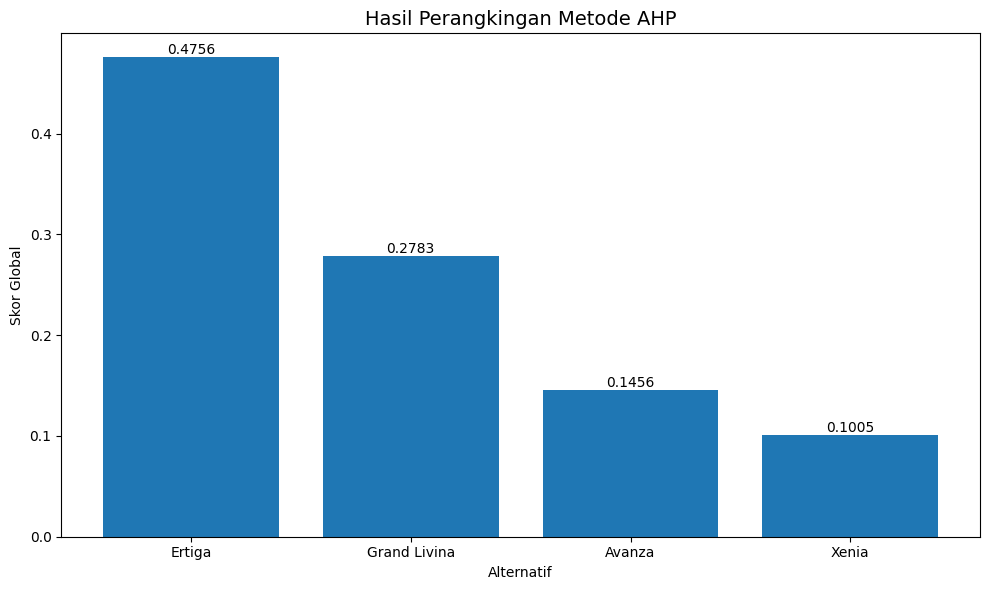

In [13]:
# ============================================================
# 13. VISUALISASI HASIL PERANGKINGAN
# ============================================================

# Mengatur ukuran grafik.
plt.figure(figsize=(10, 6))


# Membuat grafik batang.
plt.bar(
    df_hasil.index,
    df_hasil["Skor Global"]
)


# Memberikan judul dan label.
plt.title(
    "Hasil Perangkingan Metode AHP",
    fontsize=14
)

plt.xlabel("Alternatif")

plt.ylabel("Skor Global")


# Menampilkan nilai di atas setiap batang.
for i, nilai in enumerate(df_hasil["Skor Global"]):

    plt.text(
        i,
        nilai,
        f"{nilai:.4f}",
        ha="center",
        va="bottom"
    )


# Mengatur tampilan grafik.
plt.tight_layout()

plt.show()

In [14]:
# ============================================================
# 14. KESIMPULAN HASIL AHP
# ============================================================

print("\n==========================================")
print("       KESIMPULAN HASIL METODE AHP")
print("==========================================")


# Mengambil alternatif dengan skor tertinggi.
alternatif_terbaik = df_hasil.index[0]

# Mengambil skor tertinggi.
skor_terbaik = df_hasil["Skor Global"].iloc[0]


# Memeriksa konsistensi seluruh matriks.
semua_konsisten = (
    df_konsistensi["Status"] == "Konsisten"
).all()


# Menampilkan tujuan keputusan.
print(f"\nTujuan keputusan : {tujuan}")


# Menampilkan alternatif terbaik.
print(f"Alternatif terbaik: {alternatif_terbaik}")


# Menampilkan skor tertinggi.
print(f"Skor global       : {skor_terbaik:.4f}")


# Menampilkan status konsistensi.
if semua_konsisten:

    print("\nStatus pengujian: Seluruh matriks konsisten.")

    print("Hasil peringkat telah memenuhi pengujian konsistensi.")

else:

    print("\nPERINGATAN!")

    print(
        "Terdapat matriks yang tidak konsisten "
        "atau belum dapat diuji konsistensinya."
    )

    print(
        "Hasil peringkat di atas bersifat sementara "
        "dan perlu ditinjau kembali."
    )


# Menampilkan seluruh peringkat.
print("\nURUTAN PERINGKAT ALTERNATIF:")

for peringkat, (nama, baris) in enumerate(
    df_hasil.iterrows(),
    start=1
):

    print(
        f"{peringkat}. {nama} "
        f"(Skor: {baris['Skor Global']:.4f})"
    )


print("\n==========================================")


       KESIMPULAN HASIL METODE AHP

Tujuan keputusan : Pembelian Mobil
Alternatif terbaik: Ertiga
Skor global       : 0.4756

PERINGATAN!
Terdapat matriks yang tidak konsisten atau belum dapat diuji konsistensinya.
Hasil peringkat di atas bersifat sementara dan perlu ditinjau kembali.

URUTAN PERINGKAT ALTERNATIF:
1. Ertiga (Skor: 0.4756)
2. Grand Livina (Skor: 0.2783)
3. Avanza (Skor: 0.1456)
4. Xenia (Skor: 0.1005)



In [ ]:
# ============================================================
# 15. EKSPOR DAN DOWNLOAD HASIL AHP
# ============================================================

nama_output = "hasil_AHP.xlsx"

# Menyimpan seluruh hasil perhitungan ke Excel.
with pd.ExcelWriter(
    nama_output,
    engine="openpyxl"
) as writer:

    df_input.to_excel(
        writer,
        sheet_name="Data_Input",
        index=False
    )

    bobot_kriteria.to_frame(
        name="Bobot Kriteria"
    ).to_excel(
        writer,
        sheet_name="Bobot_Kriteria"
    )

    bobot_alternatif.to_excel(
        writer,
        sheet_name="Bobot_Alternatif"
    )

    matriks_skor.to_excel(
        writer,
        sheet_name="Kontribusi_Global"
    )

    df_hasil.to_excel(
        writer,
        sheet_name="Peringkat"
    )

    df_konsistensi.to_excel(
        writer,
        sheet_name="Konsistensi",
        index=False
    )

    matriks_kriteria.to_excel(
        writer,
        sheet_name="Matriks_Kriteria"
    )

    for nomor, (nama, matriks) in enumerate(
        matriks_alternatif.items(),
        start=1
    ):

        matriks.to_excel(
            writer,
            sheet_name=f"Alternatif_{nomor}"
        )

# Mengunduh hasil secara otomatis.
files.download(nama_output)